# Machine Learning Assignment 2
## Online Shoppers Purchasing Intention Prediction Using Classification Models

### 1. Dataset Description

The **Online Shoppers Purchasing Intention Dataset** is obtained from the UCI Machine Learning Repository (Dataset ID: 468).

The dataset contains information about visitors browsing an online shopping website. It includes details such as the number of pages visited, time spent on different pages, bounce rates, exit rates, visitor types, and other browsing-related information.

The dataset contains **12,330 records, 17 input features, and 1 target variable**.

The target variable is **Revenue**, which indicates whether an online shopping session resulted in a purchase.

- **Revenue = True (1):** The visitor completed a purchase.
- **Revenue = False (0):** The visitor did not complete a purchase.

The dataset contains 10,422 sessions without purchases and 1,908 sessions with purchases.

Since the target variable has only two possible outcomes, this is a **Binary Classification Problem**.

### 2. Objective of the Project

The main objective of this project is to **predict whether an online shopping visitor will make a purchase based on their browsing behaviour** using Machine Learning classification algorithms.

We will implement five classification models on the same dataset and compare their performance using different evaluation metrics.

The project also aims to identify which classification algorithm performs best for predicting customer purchasing intentions.

In [44]:
# installing ucimlrepo
!pip install -q ucimlrepo


In [45]:
# Import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import os
import py_compile

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

**Step 1: Data Understanding**

Load the dataset and examine its structure, features, target variable, and class distribution.

In [46]:

from ucimlrepo import fetch_ucirepo

# Load Online Shoppers Purchasing Intention Dataset
dataset = fetch_ucirepo(id=468)

# Features and target
X = dataset.data.features
y = dataset.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
print(y.value_counts())


Features shape: (12330, 17)
Target shape: (12330, 1)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


Revenue
False      10422
True        1908
Name: count, dtype: int64


**Step 2: Data Preprocessing**

Check for missing values and duplicate records, convert categorical features into numerical representations, and apply feature scaling where required.

In [47]:

# Check missing values in each feature
print("Missing values in features:")
print(X.isnull().sum())

Missing values in features:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
dtype: int64


In [48]:
# Check missing values in target
print("\nMissing values in target:")
print(y.isnull().sum())



Missing values in target:
Revenue    0
dtype: int64


In [49]:

# Check feature data types
print("\nFeature data types:")
print(X.dtypes)


Feature data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
dtype: object


In [50]:

# Combine features and target for duplicate checking

df = pd.concat([X, y], axis=1)

print("Total rows:", df.shape[0])
print("Duplicate rows:", df.duplicated().sum())

# We are checking duplicates, but do not delete them yet. Some online shopping sessions can legitimately have identical feature values.

Total rows: 12330
Duplicate rows: 125


Prepare the target column
Machine Learning models work with numerical target labels. We'll convert:
- False → 0 (No Purchase)
- True →   1 (Purchase)

In [51]:


# Convert Revenue to numeric labels
y = y["Revenue"].astype(int)

print("Target values:")
print(y.value_counts())


Target values:
Revenue
0    10422
1     1908
Name: count, dtype: int64


**Step 3: Train-Test Split**

Divide the dataset into 80% training data and 20% testing data.

In [52]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training records: 9864
Testing records: 2466

Training target distribution:
Revenue
0    8338
1    1526
Name: count, dtype: int64

Testing target distribution:
Revenue
0    2084
1     382
Name: count, dtype: int64


Identify categorical and numerical features

In [53]:
#To dentify feature types

categorical_columns = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nNumber of categorical columns:",
      len(categorical_columns))

print("Number of numerical columns:",
      len(numerical_columns))


Categorical columns:
['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Numerical columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

Number of categorical columns: 7
Number of numerical columns: 10


**Build the preprocessing pipeline**

In [54]:
# Convert categories into numerical columns
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Scale numerical columns
numerical_transformer = StandardScaler()

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer,
         numerical_columns),
        ("cat", categorical_transformer,
         categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


** Step 4 & 5: Machine Learning Model Implementation and Model Evaluation **

Implement the following five classification algorithms:

*   Logistic Regression
*   Decision Tree Classifier
*   K-Nearest Neighbors (KNN)
*   Gaussian Naive Bayes
*   Support Vector Machine (SVM)

**Model Evaluation**

Evaluate each classification model using six performance metrics:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)




In [55]:
# Model 1 - Logistic Regression

# Create a Logistic Regression model pipeline
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Predict on test data
y_pred = logistic_model.predict(X_test)

# Calculate probability of purchase
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Logistic Regression Results :")
print("---------------------------")
print()
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))
print("Precision:", precision_score(y_test, y_pred,
                                    zero_division=0))
print("Recall:", recall_score(y_test, y_pred,
                              zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred,
                            zero_division=0))
print("MCC:", matthews_corrcoef(y_test, y_pred))


Logistic Regression Results :
---------------------------

Accuracy: 0.8807785888077859
AUC: 0.8827868275869
Precision: 0.7365591397849462
Recall: 0.3586387434554974
F1 Score: 0.4823943661971831
MCC: 0.45916112644753304


Decision Tree Evaluation Results : 
--------------------------------

Accuracy  : 0.8990
AUC       : 0.9172
Precision : 0.7111
Recall    : 0.5864
F1 Score  : 0.6428
MCC       : 0.5883



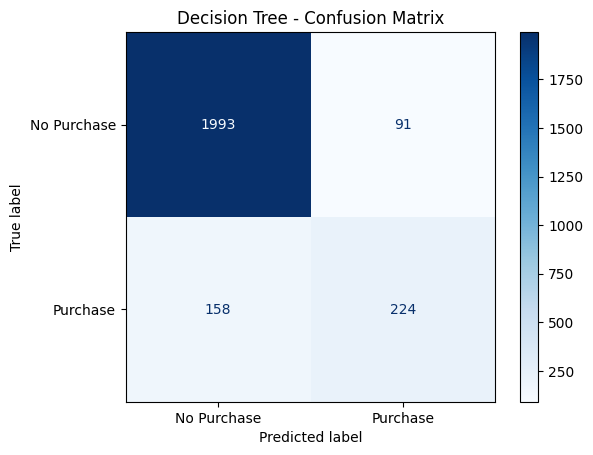

In [56]:
# Model 2 - Decision Tree Classifier

# Create Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

# Train Decision Tree
decision_tree_model.fit(X_train, y_train)

# Predict test data
dt_pred = decision_tree_model.predict(X_test)

# Predict purchase probabilities
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

# Evaluate the model
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)
dt_precision = precision_score(
    y_test, dt_pred, zero_division=0
)
dt_recall = recall_score(
    y_test, dt_pred, zero_division=0
)
dt_f1 = f1_score(
    y_test, dt_pred, zero_division=0
)
dt_mcc = matthews_corrcoef(y_test, dt_pred)

print("Decision Tree Evaluation Results : ")
print("--------------------------------")
print()
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"AUC       : {dt_auc:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"MCC       : {dt_mcc:.4f}")

print()

#ConfusionMatrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()
print()




KNN Evaluation Results : 
----------------------

Accuracy  : 0.8767
AUC       : 0.7633
Precision : 0.6822
Recall    : 0.3822
F1 Score  : 0.4899
MCC       : 0.4493



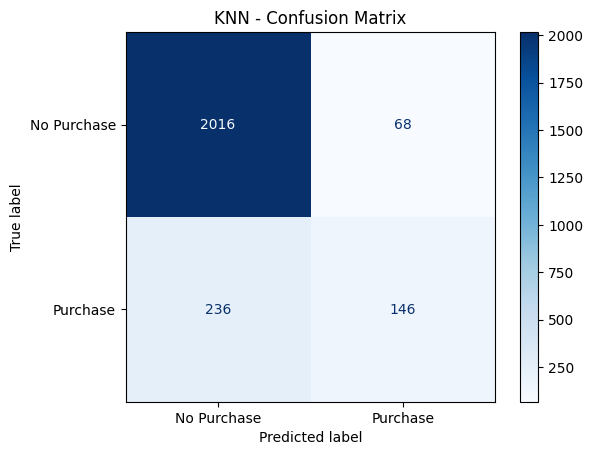

In [57]:
# Model 3 - K-Nearest Neighbors Classifier

# Create KNN model pipeline
knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the KNN model
knn_model.fit(X_train, y_train)

# Predict test data
knn_pred = knn_model.predict(X_test)

# Predict purchase probabilities
knn_prob = knn_model.predict_proba(X_test)[:, 1]


#Evaluation the model

knn_accuracy = accuracy_score(y_test, knn_pred)

knn_auc = roc_auc_score(y_test, knn_prob)

knn_precision = precision_score(
    y_test, knn_pred, zero_division=0
)

knn_recall = recall_score(
    y_test, knn_pred, zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_pred, zero_division=0
)

knn_mcc = matthews_corrcoef(y_test, knn_pred)

print("KNN Evaluation Results : ")
print("----------------------")
print()
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"AUC       : {knn_auc:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")
print(f"MCC       : {knn_mcc:.4f}")
print()


# Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.show()
print()


Gaussian Naive Bayes Results
Accuracy : 0.2729
AUC      : 0.7334
Precision: 0.1726
Recall   : 0.9738
F1 Score : 0.2933
MCC      : 0.1289


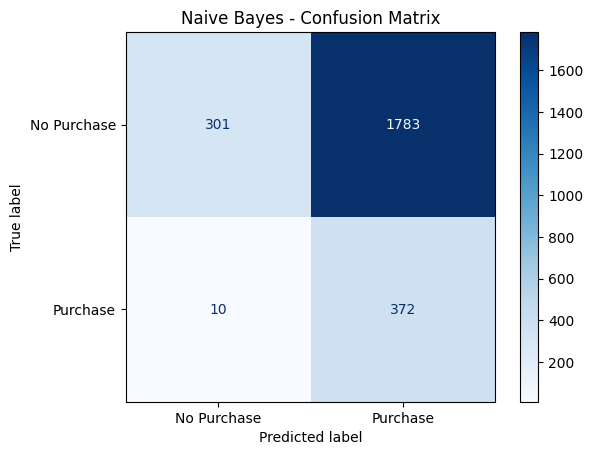

In [58]:

# Model 4: Gaussian Naive Bayes

# Preprocessing for Gaussian Naive Bayes
nb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ],
    sparse_threshold=0
)

# Create model pipeline
nb_model = Pipeline([
    ("preprocessing", nb_preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]

# Evaluate model
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_auc = roc_auc_score(y_test, nb_prob)
nb_precision = precision_score(
    y_test, nb_pred, zero_division=0
)
nb_recall = recall_score(
    y_test, nb_pred, zero_division=0
)
nb_f1 = f1_score(
    y_test, nb_pred, zero_division=0
)
nb_mcc = matthews_corrcoef(y_test, nb_pred)

print("Gaussian Naive Bayes Results")
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"AUC      : {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1 Score : {nb_f1:.4f}")
print(f"MCC      : {nb_mcc:.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("Naive Bayes - Confusion Matrix")
plt.show()


Support Vector Machine Evaluation Results : 
-----------------------------------------
Accuracy  : 0.8873
AUC       : 0.8824
Precision : 0.7047
Recall    : 0.4686
F1 Score  : 0.5629
MCC       : 0.5149



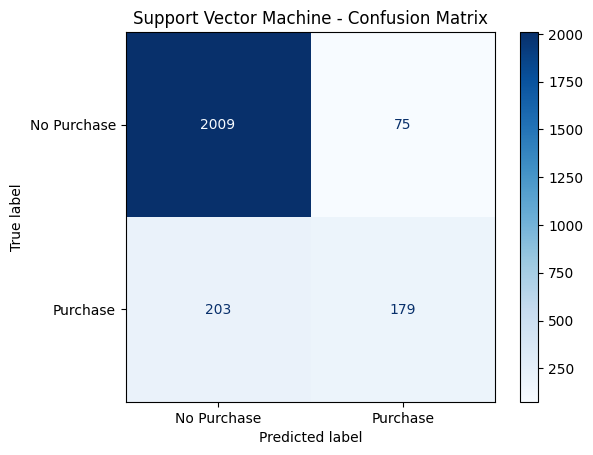

In [59]:

#Model 5 - Support Vector Machine Classifier


# Create SVM model pipeline
svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

#Train SVM model
svm_model.fit(X_train, y_train)

#Predict test data
svm_pred = svm_model.predict(X_test)

# Predict purchase probabilities
svm_prob = svm_model.predict_proba(X_test)[:, 1]


#Evaluation the model

svm_accuracy = accuracy_score(y_test, svm_pred)

svm_auc = roc_auc_score(y_test, svm_prob)

svm_precision = precision_score(
    y_test, svm_pred, zero_division=0
)

svm_recall = recall_score(
    y_test, svm_pred, zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_pred, zero_division=0
)

svm_mcc = matthews_corrcoef(y_test, svm_pred)

print("Support Vector Machine Evaluation Results : ")
print("-----------------------------------------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"AUC       : {svm_auc:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")
print(f"MCC       : {svm_mcc:.4f}")
print()

#Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_pred,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)

plt.title("Support Vector Machine - Confusion Matrix")
plt.show()

print()


In [60]:

#Save all five trained models

import os
import joblib

# Create a folder to store trained models
os.makedirs("model", exist_ok=True)

models = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

# Save each trained pipeline
for name, model in models.items():
    joblib.dump(model, f"model/{name}.joblib")
    print(f"Saved: model/{name}.joblib")

print("\nAll five models saved successfully!")


Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/svm.joblib

All five models saved successfully!


In [61]:

#Save test dataset

import pandas as pd

test_data = X_test.copy()

# Add actual target values
test_data["Revenue"] = y_test

# Save CSV without index
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)

display(test_data.head())


Test dataset saved successfully!
Shape: (2466, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
4722,1,4.0,0,0.0,13,161.166667,0.024615,0.061538,0.000000,0.6,May,2,5,9,5,Returning_Visitor,False,0
6835,1,23.2,0,0.0,23,290.000000,0.000000,0.033333,0.000000,0.0,Jul,2,2,8,3,Returning_Visitor,False,0
5524,0,0.0,0,0.0,6,95.000000,0.028571,0.028571,86.336233,0.0,Oct,1,1,4,2,New_Visitor,False,1
663,0,0.0,0,0.0,2,17.000000,0.000000,0.100000,0.000000,0.0,Mar,1,1,8,3,Returning_Visitor,False,0
136,0,0.0,0,0.0,9,303.666667,0.005556,0.046296,0.000000,0.0,Feb,2,4,5,2,Returning_Visitor,False,0


**Step 6: Model Comparison**

Compare the results of all five models, analyze their performance, and identify the best-performing model for the selected dataset.


In [62]:

#Compare all five ML models

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Store predictions and probabilities
model_results = {
    "Logistic Regression": (y_pred, y_prob),
    "Decision Tree": (dt_pred, dt_prob),
    "KNN": (knn_pred, knn_prob),
    "Naive Bayes": (nb_pred, nb_prob),
    "Support Vector Machine": (svm_pred, svm_prob)
}

# Calculate all six metrics
results = []

for model_name, (pred, prob) in model_results.items():

    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, pred)
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

print("Final Model Comparison Table")
display(comparison_df.round(4))


Final Model Comparison Table


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592
1,Decision Tree,0.8990,0.9172,0.7111,0.5864,0.6428,0.5883
2,KNN,0.8767,0.7633,0.6822,0.3822,0.4899,0.4493
3,Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289
4,Support Vector Machine,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149


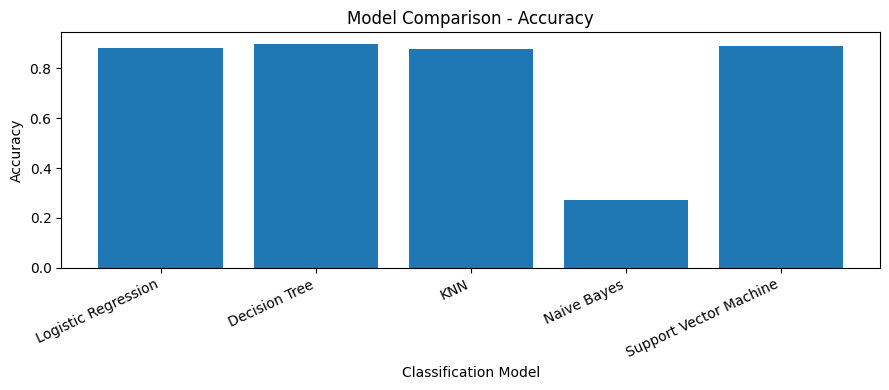

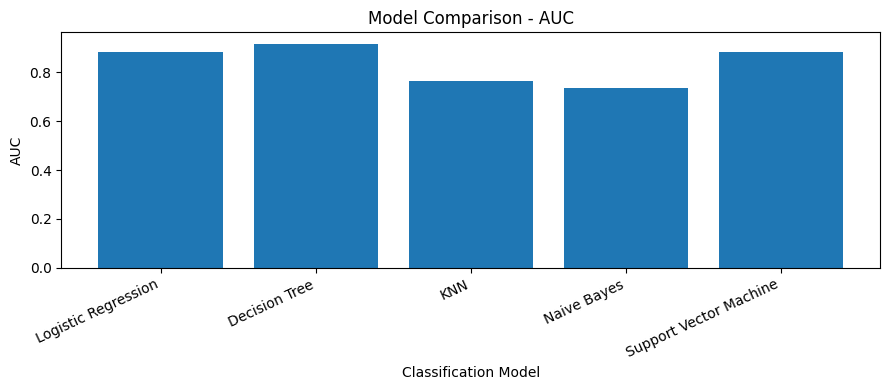

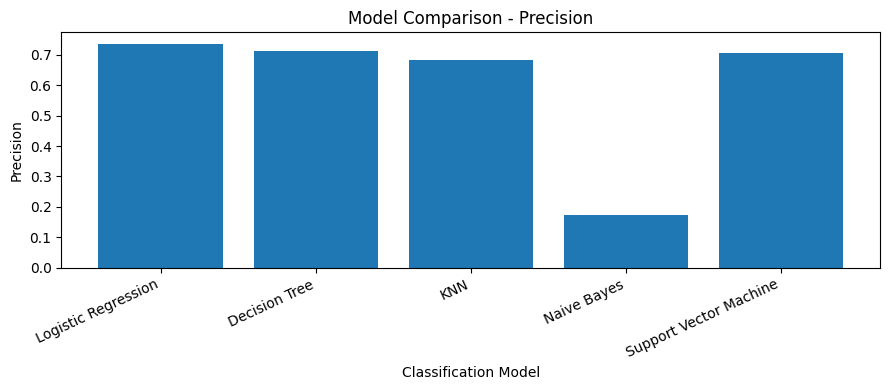

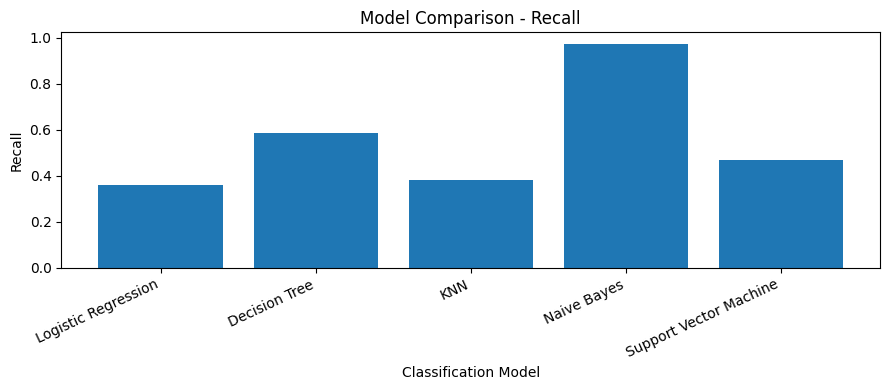

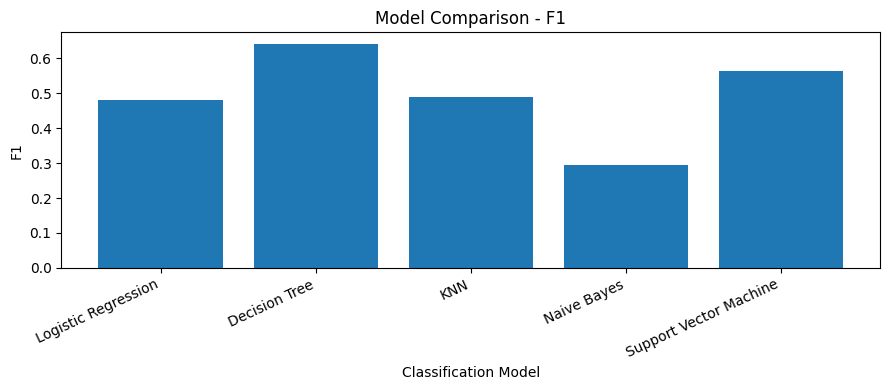

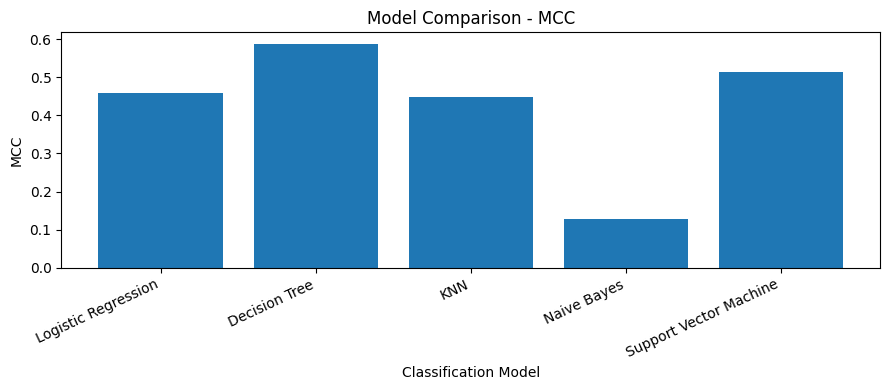

In [63]:

#Visualize model comparison

import matplotlib.pyplot as plt

metrics = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1", "MCC"
]

for metric in metrics:
    plt.figure(figsize=(9, 4))

    plt.bar(
        comparison_df["ML Model Name"],
        comparison_df[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Model")
    plt.ylabel(metric)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


In [64]:
#Generate basic performance observations

for _, row in comparison_df.iterrows():

    print("\nModel:", row["ML Model Name"])

    print(
        f"Accuracy = {row['Accuracy']:.4f}, "
        f"AUC = {row['AUC']:.4f}"
    )

    print(
        f"Precision = {row['Precision']:.4f}, "
        f"Recall = {row['Recall']:.4f}"
    )

    print(
        f"F1 = {row['F1']:.4f}, "
        f"MCC = {row['MCC']:.4f}"
    )

    if row["Recall"] < 0.5:
        print(
            "Observation: The model misses more "
            "than half of actual purchase sessions."
        )
    else:
        print(
            "Observation: The model identifies "
            "at least half of actual purchase sessions."
        )

# Define the best model based on F1 Score
best_model = comparison_df.loc[comparison_df["F1"].idxmax()]

print("\nOverall Winner:",
      best_model["ML Model Name"])


Model: Logistic Regression
Accuracy = 0.8808, AUC = 0.8828
Precision = 0.7366, Recall = 0.3586
F1 = 0.4824, MCC = 0.4592
Observation: The model misses more than half of actual purchase sessions.

Model: Decision Tree
Accuracy = 0.8990, AUC = 0.9172
Precision = 0.7111, Recall = 0.5864
F1 = 0.6428, MCC = 0.5883
Observation: The model identifies at least half of actual purchase sessions.

Model: KNN
Accuracy = 0.8767, AUC = 0.7633
Precision = 0.6822, Recall = 0.3822
F1 = 0.4899, MCC = 0.4493
Observation: The model misses more than half of actual purchase sessions.

Model: Naive Bayes
Accuracy = 0.2729, AUC = 0.7334
Precision = 0.1726, Recall = 0.9738
F1 = 0.2933, MCC = 0.1289
Observation: The model identifies at least half of actual purchase sessions.

Model: Support Vector Machine
Accuracy = 0.8873, AUC = 0.8824
Precision = 0.7047, Recall = 0.4686
F1 = 0.5629, MCC = 0.5149
Observation: The model misses more than half of actual purchase sessions.

Overall Winner: Decision Tree


In [65]:

# Save final model comparison
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Final comparison saved successfully!")

# Confirm the winning model
best_model = comparison_df.loc[
    comparison_df["F1"].idxmax()
]

print("\nBest Model:", best_model["ML Model Name"])
print("F1 Score:", round(best_model["F1"], 4))
print("Accuracy:", round(best_model["Accuracy"], 4))
print("AUC:", round(best_model["AUC"], 4))
print("MCC:", round(best_model["MCC"], 4))


Final comparison saved successfully!

Best Model: Decision Tree
F1 Score: 0.6428
Accuracy: 0.899
AUC: 0.9172
MCC: 0.5883



**Step 7: Streamlit Application Development**

Develop an interactive Streamlit application where users can upload a test CSV file, select a trained classification model, and view its performance metrics and confusion matrix.


In [66]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, confusion_matrix
)

st.set_page_config(page_title="Online Shopping Purchase Prediction", page_icon="🛒", layout="wide")
st.markdown("""
<style>
.block-container {max-width: 1050px; padding-top: 1rem; padding-bottom: 1rem;}
h1 {font-size: 1.65rem !important;}
[data-testid="stMetricValue"] {font-size: 1.25rem;}
</style>
""", unsafe_allow_html=True)

BASE_DIR = Path(__file__).resolve().parent
MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors (KNN)": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine (SVM)": "model/svm.joblib",
}

@st.cache_resource(show_spinner=False, max_entries=2)
def load_model(model_path: str):
    return joblib.load(model_path)

st.title("🛒 Online Shopping Purchase Prediction")
st.caption("Evaluate five pretrained classification models on labeled test data. No retraining.")

with st.form("evaluation_form"):
    left, right = st.columns([1, 1.3], gap="medium")
    with left:
        selected_model = st.selectbox("Classification model", list(MODEL_FILES))
    with right:
        uploaded_file = st.file_uploader("Test CSV (including Revenue)", type=["csv"])
    run_evaluation = st.form_submit_button("Run Evaluation", type="primary")

if not run_evaluation:
    st.info("Select a model, upload **test_data.csv**, and click **Run Evaluation**.")
    st.stop()

if uploaded_file is None:
    st.error("Please upload a test CSV before running the evaluation.")
    st.stop()

try:
    test_df = pd.read_csv(uploaded_file)
except Exception as exc:
    st.error(f"Cannot read CSV: {exc}")
    st.stop()

if test_df.empty or "Revenue" not in test_df.columns:
    st.error("CSV must contain rows and a Revenue target column.")
    st.stop()

raw_target = test_df["Revenue"].astype(str).str.strip().str.lower()
y = raw_target.map({"true": 1, "false": 0, "1": 1, "0": 0})
if y.isna().any():
    st.error("Revenue must contain only True/False or 1/0, without missing values.")
    st.stop()
y = y.astype(int)
if y.nunique() != 2:
    st.error("Test CSV must include both Revenue classes (0 and 1) to calculate AUC.")
    st.stop()

X = test_df.drop(columns=["Revenue"])
if len(test_df) != 2466:
    st.warning(f"Uploaded {len(test_df):,} rows. Use the held-out test_data.csv (2,466 rows) for assignment results.")

model_path = BASE_DIR / MODEL_FILES[selected_model]
if not model_path.is_file():
    st.error(f"Model file missing: {MODEL_FILES[selected_model]}")
    st.stop()

try:
    with st.spinner("Evaluating saved model..."):
        model = load_model(str(model_path))
        if hasattr(model, "feature_names_in_"):
            expected = list(model.feature_names_in_)
        elif hasattr(model, "named_steps") and hasattr(model.named_steps.get("preprocessing"), "feature_names_in_"):
            expected = list(model.named_steps["preprocessing"].feature_names_in_)
        else:
            expected = None
        if expected is not None:
            missing = [name for name in expected if name not in X.columns]
            if missing:
                st.error("Missing input columns: " + ", ".join(missing))
                st.stop()
            X = X[expected]
        predictions = model.predict(X)
        class_labels = list(model.classes_)
        if 1 not in class_labels:
            st.error("Saved model does not contain positive class 1.")
            st.stop()
        probabilities = model.predict_proba(X)[:, class_labels.index(1)]
except Exception as exc:
    st.error(f"Model loading or prediction failed: {exc}")
    st.stop()

scores = [
    ("Accuracy", accuracy_score(y, predictions)),
    ("AUC", roc_auc_score(y, probabilities)),
    ("Precision", precision_score(y, predictions, zero_division=0)),
    ("Recall", recall_score(y, predictions, zero_division=0)),
    ("F1 Score", f1_score(y, predictions, zero_division=0)),
    ("MCC", matthews_corrcoef(y, predictions)),
]
st.subheader("Model Evaluation")
for col, (label, score) in zip(st.columns(6), scores):
    col.metric(label, f"{score:.4f}")
st.caption(f"{selected_model} · {len(test_df):,} rows · {X.shape[1]} features")

st.subheader("Confusion Matrix")
cm = confusion_matrix(y, predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
cm_table = pd.DataFrame(
    [[int(tn), int(fp)], [int(fn), int(tp)]],
    index=["Actual: No Purchase", "Actual: Purchase"],
    columns=["Predicted: No Purchase", "Predicted: Purchase"],
)
st.table(cm_table)
st.caption(f"TN = {tn:,} · FP = {fp:,} · FN = {fn:,} · TP = {tp:,}")

with st.expander("Evaluation metric formulas"):
    st.latex(r"Accuracy = \frac{TP+TN}{TP+TN+FP+FN}")
    st.latex(r"Precision = \frac{TP}{TP+FP}")
    st.latex(r"Recall = \frac{TP}{TP+FN}")
    st.latex(r"F1 = \frac{2\cdot Precision\cdot Recall}{Precision+Recall}")
    st.latex(r"MCC = \frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}")
    st.markdown("**AUC:** Area under the ROC curve across decision thresholds; calculated from predicted probabilities.")


Overwriting app.py


In [67]:

%%writefile requirements.txt
streamlit
scikit-learn
pandas
numpy
matplotlib
joblib
scipy


Overwriting requirements.txt


In [68]:
print("Project files:")
print(os.listdir("."))

print("\nSaved models:")

if os.path.exists("model"):
    print(os.listdir("model"))
else:
    print("Model folder not found!")

Project files:
['.config', 'model_comparison.csv', 'test_data.csv', 'app.py', 'streamlit.log', 'project_files.zip', 'requirements.txt', '__pycache__', 'model', 'sample_data']

Saved models:
['decision_tree.joblib', 'logistic_regression.joblib', 'knn.joblib', 'svm.joblib', 'naive_bayes.joblib']


In [69]:
!python -m py_compile app.py
print("Python syntax check completed.")

Python syntax check completed.


In [70]:

try:
    py_compile.compile("app.py", doraise=True)
    print("SUCCESS: app.py syntax is correct!")
except Exception as e:
    print("ERROR:", e)

SUCCESS: app.py syntax is correct!


In [71]:

import joblib

for name in models:
    path = f"model/{name}.joblib"
    loaded_model = joblib.load(path)
    prediction = loaded_model.predict(
        X_test.head(5)
    )
    print(name, "OK:", prediction)


logistic_regression OK: [0 0 1 0 0]
decision_tree OK: [0 0 1 0 0]
knn OK: [0 0 1 0 0]
naive_bayes OK: [1 1 1 1 0]
svm OK: [0 0 1 0 0]


In [72]:

import sklearn
import pandas
import numpy
import scipy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)
print("joblib:", joblib.__version__)


scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
scipy: 1.16.3
joblib: 1.6.0


In [73]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, f1_score

# Load test CSV
test_df = pd.read_csv("test_data.csv")

# Separate features and target
X_app = test_df.drop(columns=["Revenue"])
y_app = test_df["Revenue"].astype(int)

# Define the names of the models from the active models dictionary
model_names = list(models.keys())

# Test every saved model
for name in model_names:

    model = joblib.load(f"model/{name}.joblib")

    predictions = model.predict(X_app)

    accuracy = accuracy_score(y_app, predictions)
    f1 = f1_score(y_app, predictions)

    print(f"\nModel: {name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 Score: {f1:.4f}")

print("\nAll saved models tested!")


Model: logistic_regression
Accuracy: 0.8808
F1 Score: 0.4824

Model: decision_tree
Accuracy: 0.8990
F1 Score: 0.6428

Model: knn
Accuracy: 0.8767
F1 Score: 0.4899

Model: naive_bayes
Accuracy: 0.2729
F1 Score: 0.2933

Model: svm
Accuracy: 0.8873
F1 Score: 0.5629

All saved models tested!


In [74]:

!pip -q install streamlit


In [75]:

import py_compile

try:
    py_compile.compile("app.py", doraise=True)
    print("SUCCESS: app.py syntax is correct!")
except Exception as error:
    print("ERROR:", error)


SUCCESS: app.py syntax is correct!


In [76]:

import subprocess

subprocess.run(
    ["pkill", "-f", "streamlit run"],
    check=False
)

print("Previous Streamlit server stopped.")


Previous Streamlit server stopped.


In [77]:

import subprocess
import time

log_file = open("streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        "app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Process running:",
      streamlit_process.poll() is None)


Process running: True


In [78]:

import requests

response = requests.get(
    "http://localhost:8501/_stcore/health",
    timeout=10
)

print("Status:", response.status_code)
print("Response:", response.text)


Status: 200
Response: ok


In [79]:

from google.colab import output

output.serve_kernel_port_as_window(8501)


Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [80]:

# Check the Streamlit error log

with open("streamlit.log", "r") as file:
    print(file.read()[-5000:])




2026-11-03 18:25:03.005 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.138.7.72:8501




In [81]:
!zip -r project_files.zip model test_data.csv model_comparison.csv
from google.colab import files
files.download("project_files.zip")

updating: model/ (stored 0%)
updating: model/decision_tree.joblib (deflated 59%)
updating: model/logistic_regression.joblib (deflated 52%)
updating: model/knn.joblib (deflated 83%)
updating: model/svm.joblib (deflated 76%)
updating: model/naive_bayes.joblib (deflated 45%)
updating: test_data.csv (deflated 76%)
updating: model_comparison.csv (deflated 42%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>